In [28]:
import pandas as pd

# prepare 1D Data series

one_dseries =pd.Series([1,2,3])
one_dseries


,0
0,1
1,2
2,3


In [29]:
data1 =pd.Series({'India':100,'USA':200})
data1

,0
India,100
USA,200


In [30]:
data2 = pd.DataFrame({
    'SrNo':[1,2,3,4,5,6,7,8,9,10],
    'Name':['A','B','C','D','E','F','G','H','I','J'],
    'Marks':[10,20,30,40,50,60,70,80,90,100],
    'CGPA':[9,8,7,6,5,4,3,2,1,9]
})
data2

,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,6
4,5,E,50,5
5,6,F,60,4
6,7,G,70,3
7,8,H,80,2
8,9,I,90,1
9,10,J,100,9


In [31]:
#checking dataset information
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   SrNo    10 non-null     int64 
 1   Name    10 non-null     object
 2   Marks   10 non-null     int64 
 3   CGPA    10 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 452.0+ bytes


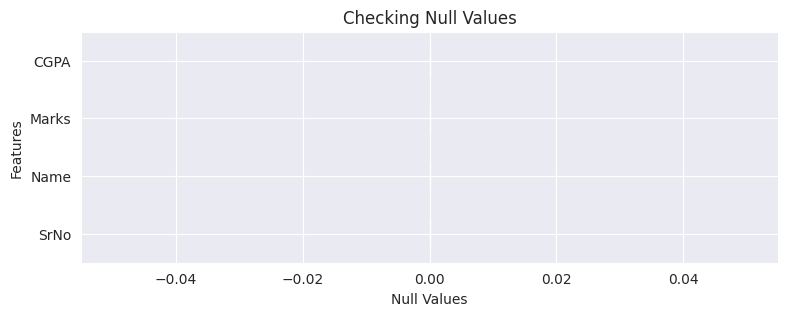

In [32]:
#checking null values information
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('darkgrid')

plt.figure(figsize=(9,3))
data2.isnull().sum().plot(kind='barh')
plt.title('Checking Null Values')
plt.xlabel('Null Values')
plt.ylabel('Features')
plt.show()


In [33]:
#checking duplicate values
data2.duplicated()   # helps use to check duplicate records present in dataset
data2.drop_duplicates() # this will drop the dupicated record from the dataset


,SrNo,Name,Marks,CGPA
0,1,A,10,9
1,2,B,20,8
2,3,C,30,7
3,4,D,40,6
4,5,E,50,5
5,6,F,60,4
6,7,G,70,3
7,8,H,80,2
8,9,I,90,1
9,10,J,100,9


In [34]:
#checking descriptive stats for numerical data
data2.describe(exclude='object')

,SrNo,Marks,CGPA
count,10.00000,10.000000,10.000000
mean,5.50000,55.000000,5.400000
std,3.02765,30.276504,2.875181
min,1.00000,10.000000,1.000000
25%,3.25000,32.500000,3.250000
50%,5.50000,55.000000,5.500000
75%,7.75000,77.500000,7.750000
max,10.00000,100.000000,9.000000


In [35]:
#checking descriptive stats for categorical data
data2.describe(include='object')

,Name
count,10
unique,10
top,A
freq,1


In [50]:
from numpy import quantile
#checking descriptive stats using column orderedict function
#step1: segregate categorical data and numerical data

numerical_col =data2.select_dtypes(exclude='object').columns
categorical_col = data2.select_dtypes(include='object').columns

stats=[]
from collections import OrderedDict
for i in numerical_col:
  numerical_stats = OrderedDict({
      'Feature':i,
      'count':data2[i].count(),
      '% of Missing value':(data2[i].isnull().sum()/len(data2)) * 100,
      'Maximum':data2[i].max(),
      'Minmum':data2[i].min(),
      'Mean':data2[i].mean(),
      'Median':data2[i].median(),
      'Q1':data2[i].quantile(0.25),
      'Q3':data2[i].quantile(0.75),
      'IQR':data2[i].quantile(0.75)-data2[i].quantile(0.25),
      'Standard Deviation':data2[i].std(),
      'Variance':data2[i].var(),
      'skewness':data2[i].skew(),
      'kurtosis':data2[i].kurtosis()
  })
  stats.append(numerical_stats)
  report = pd.DataFrame(stats)

report

,Feature,count,% of Missing value,Maximum,Minmum,Mean,Median,Q1,Q3,IQR,Standard Deviation,Variance,skewness,kurtosis
0,SrNo,10,0.0,10,1,5.5,5.5,3.25,7.75,4.5,3.027650,9.166667,0.000000,-1.200000
1,Marks,10,0.0,100,10,55.0,55.0,32.50,77.50,45.0,30.276504,916.666667,0.000000,-1.200000
2,CGPA,10,0.0,9,1,5.4,5.5,3.25,7.75,4.5,2.875181,8.266667,-0.151463,-1.356985


In [51]:
#saving report file as CSV
report.to_csv('report.csv')

<Axes: >

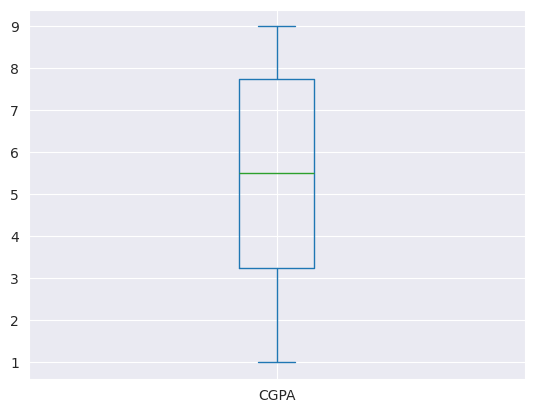

In [52]:
data2['CGPA'].plot(kind='box')

<Axes: ylabel='Density'>

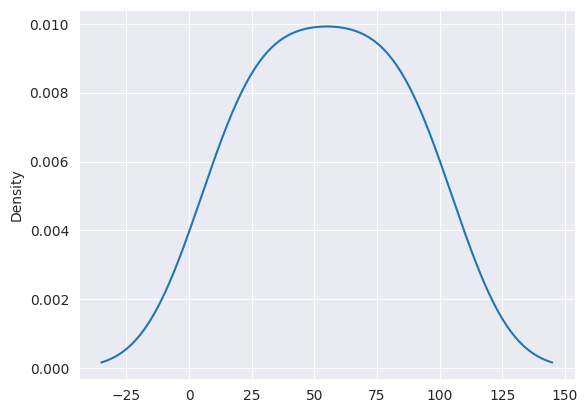

In [53]:
data2['Marks'].plot(kind='kde')